In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from underthesea import word_tokenize
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack

/home/peterjohn/miniconda3/envs/ai_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('auto_labeled_comments.csv')
print(df.info())
print(df['label'].value_counts())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4161 entries, 0 to 4160
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  4161 non-null   object
 1   label    4161 non-null   object
dtypes: object(2)
memory usage: 65.1+ KB
None
label
ham     3580
spam     581
Name: count, dtype: int64


,content,label
0,"k chăm chỉ là đc e, lên là các thầy cho vào ngay",ham
1,Phan Bảo Hai Anh neu m biet m se biet,ham
2,Tôi có,ham
3,giỏi,ham
4,Xứt sắc,ham


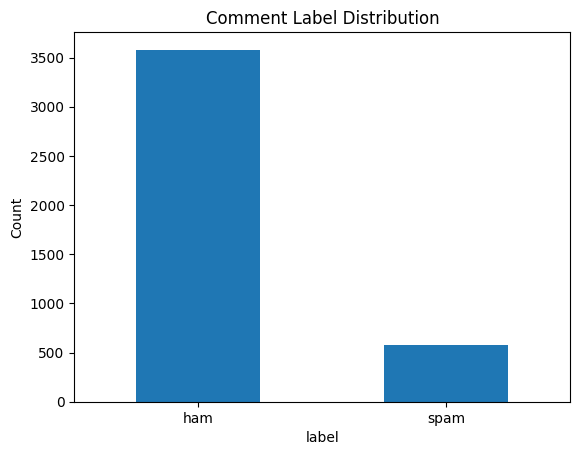

In [3]:
df['label'].value_counts().plot(kind='bar', rot=0)
plt.title('Comment Label Distribution')
plt.ylabel('Count')
plt.show()

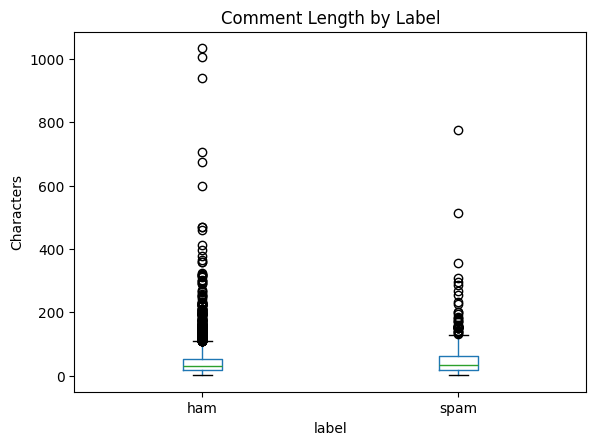

In [4]:
df['char_len'] = df['content'].astype(str).str.len()
df.boxplot(column='char_len', by='label', grid=False)
plt.title('Comment Length by Label')
plt.suptitle('')
plt.ylabel('Characters')
plt.show()

In [5]:
STOPWORDS = {'là', 'thì', 'và', 'của', 'những', 'các', 'một', 'được', 'với', 'ở', 'này', 'đó', 'cho'}

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' token_url ', text)
    text = re.sub(r'(?:(?:\+|00)?84|0)(?:\d[\s\.]?){8,10}\d', ' token_sdt ', text)
    text = re.sub(r'\b(i[\.\s]?b|inbox|inb|zalo|zl|lh|liên hệ)\b', ' token_lienhe ', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    tokens = word_tokenize(text, format='text').split()
    return ' '.join(w for w in tokens if w not in STOPWORDS)

df['processed'] = df['content'].apply(preprocess)
display(df[['content', 'processed', 'label']].head())

,content,processed,label
0,"k chăm chỉ là đc e, lên là các thầy cho vào ngay",k chăm_chỉ đc e lên thầy vào ngay,ham
1,Phan Bảo Hai Anh neu m biet m se biet,phan_bảo hai anh neu m biet m se biet,ham
2,Tôi có,tôi có,ham
3,giỏi,giỏi,ham
4,Xứt sắc,xứt sắc,ham


In [6]:
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df['label'])
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
print(pd.DataFrame({'Train': train['label'].value_counts(), 'Test': test['label'].value_counts()}))

       Train  Test
label             
ham     2863   717
spam     465   116


In [7]:
vec_bow = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_train_bow = vec_bow.fit_transform(train['processed'])
X_test_bow = vec_bow.transform(test['processed'])

vec_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = vec_tfidf.fit_transform(train['processed'])
X_test_tfidf = vec_tfidf.transform(test['processed'])

sentences = [s.split() for s in train['processed']]
w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4, epochs=30, seed=42)

def doc_vector_avg(tokens):
    vecs = [w2v_model.wv[w] for w in tokens if w in w2v_model.wv]
    return np.mean(vecs, axis=0) if len(vecs) > 0 else np.zeros(w2v_model.vector_size)

X_train_w2v_avg = np.array([doc_vector_avg(s.split()) for s in train['processed']])
X_test_w2v_avg = np.array([doc_vector_avg(s.split()) for s in test['processed']])

tfidf_uni = TfidfVectorizer(ngram_range=(1, 1), min_df=1)
tfidf_uni.fit(train['processed'])
idf_dict = dict(zip(tfidf_uni.get_feature_names_out(), tfidf_uni.idf_))

def doc_vector_tfidf_avg(tokens):
    vecs, weights = [], []
    for w in tokens:
        if w in w2v_model.wv:
            weight = idf_dict.get(w, 1.0)
            vecs.append(w2v_model.wv[w] * weight)
            weights.append(weight)
    return np.sum(vecs, axis=0) / sum(weights) if (len(vecs) > 0 and sum(weights) > 0) else np.zeros(w2v_model.vector_size)

X_train_w2v_tfidf = np.array([doc_vector_tfidf_avg(s.split()) for s in train['processed']])
X_test_w2v_tfidf = np.array([doc_vector_tfidf_avg(s.split()) for s in test['processed']])

X_train_combined = hstack([X_train_tfidf, X_train_w2v_tfidf]).tocsr()
X_test_combined = hstack([X_test_tfidf, X_test_w2v_tfidf]).tocsr()

In [8]:
experiments = {
    ('BoW', 'LinearSVC'): (X_train_bow, X_test_bow, LinearSVC(dual='auto', max_iter=3000, random_state=42)),
    ('BoW', 'LogisticRegression'): (X_train_bow, X_test_bow, LogisticRegression(max_iter=1000, random_state=42)),
    ('TF-IDF', 'LinearSVC'): (X_train_tfidf, X_test_tfidf, LinearSVC(dual='auto', max_iter=3000, random_state=42)),
    ('TF-IDF', 'LogisticRegression'): (X_train_tfidf, X_test_tfidf, LogisticRegression(max_iter=1000, random_state=42)),
    ('Word2Vec Avg', 'LinearSVC'): (X_train_w2v_avg, X_test_w2v_avg, LinearSVC(dual='auto', class_weight='balanced', C=0.5, max_iter=3000, random_state=42)),
    ('Word2Vec Avg', 'LogisticRegression'): (X_train_w2v_avg, X_test_w2v_avg, LogisticRegression(class_weight='balanced', C=1.0, max_iter=1000, random_state=42)),
    ('Word2Vec TF-IDF Avg', 'LinearSVC'): (X_train_w2v_tfidf, X_test_w2v_tfidf, LinearSVC(dual='auto', class_weight='balanced', C=0.5, max_iter=3000, random_state=42)),
    ('Word2Vec TF-IDF Avg', 'LogisticRegression'): (X_train_w2v_tfidf, X_test_w2v_tfidf, LogisticRegression(class_weight='balanced', C=1.0, max_iter=1000, random_state=42)),
    ('TF-IDF + Word2Vec', 'LinearSVC'): (X_train_combined, X_test_combined, LinearSVC(dual='auto', max_iter=3000, random_state=42)),
    ('TF-IDF + Word2Vec', 'LogisticRegression'): (X_train_combined, X_test_combined, LogisticRegression(max_iter=1000, random_state=42))
}

results = []
predictions = {}
for (feat, algo), (X_tr, X_te, clf) in experiments.items():
    clf.fit(X_tr, train['label'])
    y_pred = clf.predict(X_te)
    predictions[(feat, algo)] = y_pred
    acc = accuracy_score(test['label'], y_pred)
    prec = precision_score(test['label'], y_pred, average='macro', zero_division=0)
    rec = recall_score(test['label'], y_pred, average='macro', zero_division=0)
    f1 = f1_score(test['label'], y_pred, average='macro', zero_division=0)
    results.append({
        'Feature': feat,
        'Model': algo,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'Macro F1': f1
    })

scores_df = pd.DataFrame(results)
display(scores_df)

,Feature,Model,Accuracy,Precision,Recall,Macro F1
0,BoW,LinearSVC,0.929172,0.875523,0.810724,0.838605
1,BoW,LogisticRegression,0.926771,0.884329,0.787651,0.825943
2,TF-IDF,LinearSVC,0.930372,0.892579,0.796969,0.835218
3,TF-IDF,LogisticRegression,0.905162,0.899735,0.677548,0.731388
4,Word2Vec Avg,LinearSVC,0.884754,0.763941,0.860794,0.798500
5,Word2Vec Avg,LogisticRegression,0.870348,0.743679,0.841587,0.776968
6,Word2Vec TF-IDF Avg,LinearSVC,0.888355,0.768963,0.862887,0.803171
7,Word2Vec TF-IDF Avg,LogisticRegression,0.860744,0.731510,0.832396,0.764207
8,TF-IDF + Word2Vec,LinearSVC,0.935174,0.895304,0.817823,0.850439
9,TF-IDF + Word2Vec,LogisticRegression,0.906363,0.836030,0.732440,0.770416


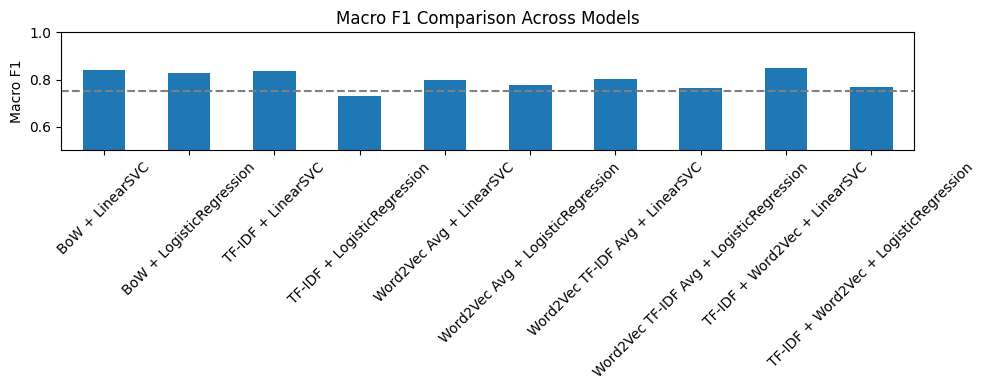

In [9]:
model_names = scores_df['Feature'] + ' + ' + scores_df['Model']
scores_df.set_index(model_names)['Macro F1'].plot(kind='bar', figsize=(10, 4), rot=45)
plt.axhline(0.75, color='gray', linestyle='--')
plt.title('Macro F1 Comparison Across Models')
plt.ylabel('Macro F1')
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

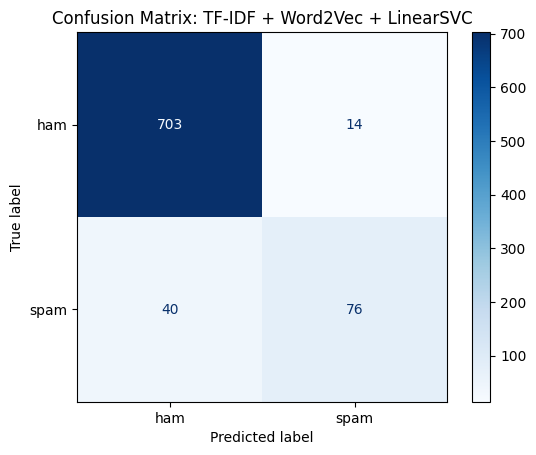

In [10]:
best_model = ('TF-IDF + Word2Vec', 'LinearSVC')
cm = confusion_matrix(test['label'], predictions[best_model], labels=['ham', 'spam'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ham', 'spam'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix: ' + best_model[0] + ' + ' + best_model[1])
plt.show()

In [11]:
print(classification_report(test['label'], predictions[best_model], digits=4))

review = test[['content', 'label']].copy()
review['pred'] = predictions[best_model]
display(review[review['label'] != review['pred']].head(10))

              precision    recall  f1-score   support

         ham     0.9462    0.9805    0.9630       717
        spam     0.8444    0.6552    0.7379       116

    accuracy                         0.9352       833
   macro avg     0.8953    0.8178    0.8504       833
weighted avg     0.9320    0.9352    0.9317       833



,content,label,pred
2988,Vị trí thuận tiện: Ngay ngã tư Trương Văn Thàn...,spam,ham
3255,Báo giá học phí trọn gói,spam,ham
1219,- NƯỚC 36.300/1khối,spam,ham
2390,Mình cần cc để quy đổi học phần tiếng anh nhắn...,spam,ham
1686,Thang bộ,spam,ham
3138,Matcha latte/ Coconut matcha/ Matcha latte xoà...,spam,ham
3884,B lh 0977.202.733 k nhận hậu tạ đâu ạ,ham,spam
1504,Bỏ ẩn danh ra để t ib đê,ham,spam
1653,Mình đăng bài hộ cô chủ nhà mọi người cần tìm ...,spam,ham
2160,Cứu dc r nhé ai cần thì để số mình chỉ qua zal...,spam,ham


label
ham     116
spam    116
Name: count, dtype: int64
Accuracy:  0.8233
Macro F1:  0.8181
              precision    recall  f1-score   support

         ham     0.7419    0.9914    0.8487       116
        spam     0.9870    0.6552    0.7876       116

    accuracy                         0.8233       232
   macro avg     0.8645    0.8233    0.8181       232
weighted avg     0.8645    0.8233    0.8181       232



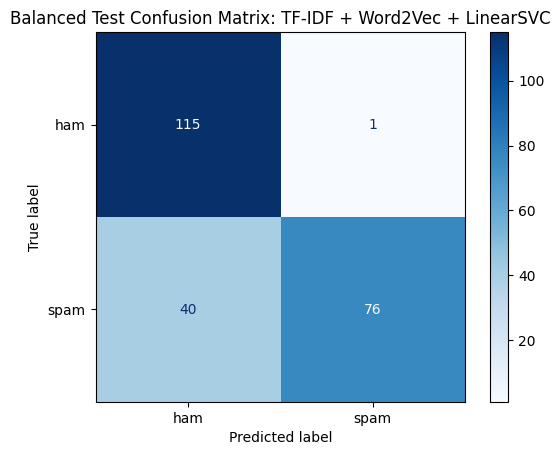

In [12]:
test_spam = test[test['label'] == 'spam']
test_ham = test[test['label'] == 'ham'].sample(n=len(test_spam), random_state=42)
test_balanced = pd.concat([test_spam, test_ham]).sample(frac=1.0, random_state=42)

idx_balanced = [test.index.get_loc(i) for i in test_balanced.index]
X_test_bal = X_test_combined[idx_balanced]

best_clf = experiments[best_model][2]
preds_bal = best_clf.predict(X_test_bal)

print(test_balanced['label'].value_counts())
print('Accuracy: ', round(accuracy_score(test_balanced['label'], preds_bal), 4))
print('Macro F1: ', round(f1_score(test_balanced['label'], preds_bal, average='macro'), 4))
print(classification_report(test_balanced['label'], preds_bal, digits=4))

cm_bal = confusion_matrix(test_balanced['label'], preds_bal, labels=['ham', 'spam'])
disp_bal = ConfusionMatrixDisplay(confusion_matrix=cm_bal, display_labels=['ham', 'spam'])
disp_bal.plot(cmap='Blues')
plt.title('Balanced Test Confusion Matrix: ' + best_model[0] + ' + ' + best_model[1])
plt.show()